# 01 数据管道与数据质量

这一节回答三个问题：数据从哪来、怎么一层层加工成分析表、哪些地方不能直接信。
后面所有分析都建立在这里定下的口径上。

**数据来源**：Kaggle 公开数据集 [eCommerce behavior data from multi category store](https://www.kaggle.com/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store)，
由 [REES46 Marketing Platform](https://rees46.com) 的 Open CDP 项目采集，是一家海外多品类电商平台 2019 年 10–11 月的用户行为日志。
原始数据不随仓库分发，`pipeline/download.py` 会从 Kaggle 下载。

In [1]:
from nbutils import *
from pathlib import Path
import numpy as np

## 1. 管道与分层

```
Kaggle API ──download.py──▶ archive.zip（4.6GB）
           ──ingest.py────▶ ODS  原始事件 Parquet（只转类型，可与原文件逐行对账）
           ──transform.py─▶ DWD  清洗后事件明细、订单明细
                            DIM  商品维表
                            DWS  用户×日汇总、用户画像、访问间隔、生命周期快照
                            ADS  日指标、品类日指标、留存 cohort、生命周期日快照、小时事件量
           ──quality_checks.py ▶ docs/data_quality_report.md
           ──export_dashboard.py ▶ dashboard/data/*.json（看板数据）
```

各层的粒度和行数：

In [2]:
tables = ["ods_events", "dwd_events", "dwd_orders", "dim_product", "dws_user_daily", "dws_user_profile",
          "dws_user_visit_interval", "dws_user_lifecycle", "ads_daily_metrics", "ads_daily_category",
          "ads_retention_cohort", "ads_lifecycle_daily", "ads_hourly_events"]
grain = {
    "ods_events": "原始文件一行", "dwd_events": "一次去重后的事件", "dwd_orders": "一笔订单（user × session）",
    "dim_product": "一个商品", "dws_user_daily": "用户 × 自然日", "dws_user_profile": "一个用户（全窗口）",
    "dws_user_visit_interval": "用户的一个活跃日 + 下一次活跃日", "dws_user_lifecycle": "一个用户（11-30 快照）",
    "ads_daily_metrics": "一个自然日", "ads_daily_category": "一级品类 × 自然日",
    "ads_retention_cohort": "cohort 日 × 第 N 天", "ads_lifecycle_daily": "快照日 × 生命周期分层",
    "ads_hourly_events": "一个小时",
}
pd.DataFrame([(t, t.split("_")[0].upper(), grain[t], q(f"SELECT COUNT(*) n FROM {t}").n[0]) for t in tables],
             columns=["表", "层", "粒度", "行数"]).style.format({"行数": "{:,}"}).hide(axis="index")

表,层,粒度,行数
ods_events,ODS,原始文件一行,"109,950,743"
dwd_events,DWD,一次去重后的事件,"109,772,653"
dwd_orders,DWD,一笔订单（user × session）,"1,402,222"
dim_product,DIM,一个商品,"206,851"
dws_user_daily,DWS,用户 × 自然日,"15,094,690"
dws_user_profile,DWS,一个用户（全窗口）,"5,315,091"
dws_user_visit_interval,DWS,用户的一个活跃日 + 下一次活跃日,"15,094,690"
dws_user_lifecycle,DWS,一个用户（11-30 快照）,"5,315,091"
ads_daily_metrics,ADS,一个自然日,61
ads_daily_category,ADS,一级品类 × 自然日,854


## 2. 口径：订单、金额、时间

| 问题 | 数据里的情况 | 定下的口径 |
|---|---|---|
| 什么算一笔订单 | 数据集说明：同一 session 里的多条 purchase 是**同一笔订单** | 订单 = 有 purchase 的 (user_id, user_session)；旧版把每条 purchase 当一单，订单数会多算 18% |
| 金额单位 | 数据集没注明币种 | GMV = purchase 事件的 price 之和，单位写「原始价格单位」 |
| 时间 | `event_time` 是 UTC，没给店铺时区 | 按流量曲线推断为 UTC+3，业务日期按本地时间切分（见下） |
| 品类 | 32% 的事件没有品类编码（数据集说明：配件类通常没有） | 记为 unknown，单列不剔除 |

In [3]:
o = q("SELECT COUNT(*) orders, SUM(items) items FROM dwd_orders")
print(f"订单 {o.orders[0]:,} 笔，purchase 事件 {o['items'][0]:,.0f} 条，每单平均 {o['items'][0] / o.orders[0]:.2f} 件；"
      f"按事件数算订单会多算 {o['items'][0] / o.orders[0] - 1:.1%}")

订单 1,402,222 笔，purchase 事件 1,658,954 条，每单平均 1.18 件；按事件数算订单会多算 18.3%


## 3. 时区推断

电商流量一般凌晨最低、晚上最高。原始时间是 UTC，直接按 UTC 划分「早中晚」会把整条曲线错开几个小时。

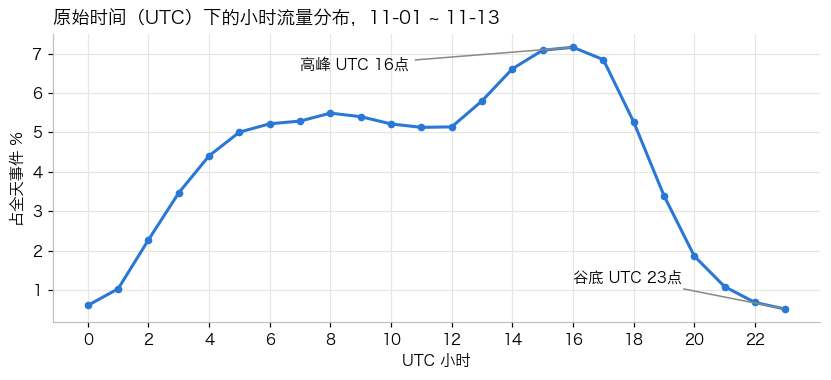

谷底 UTC 23 点、高峰 UTC 16 点；按 UTC+3 换算为本地 2 点和 19 点


In [4]:
hourly = q("""
    SELECT HOUR(event_time_utc) AS utc_hour, COUNT(*) AS events
    FROM ods_events
    WHERE event_time_utc >= '2019-11-01' AND event_time_utc < '2019-11-14'   -- 避开大促和埋点缺失
    GROUP BY 1 ORDER BY 1
""")
hourly["share"] = hourly.events / hourly.events.sum()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(hourly.utc_hour, hourly.share * 100, color=PALETTE[0], marker="o", markersize=4)
lo, hi = hourly.loc[hourly.share.idxmin(), "utc_hour"], hourly.loc[hourly.share.idxmax(), "utc_hour"]
ax.annotate(f"谷底 UTC {lo}点", (lo, hourly.share.min() * 100), xytext=(lo - 7, 1.2), arrowprops=dict(arrowstyle="-", color=GRAY))
ax.annotate(f"高峰 UTC {hi}点", (hi, hourly.share.max() * 100), xytext=(hi - 9, 6.6), arrowprops=dict(arrowstyle="-", color=GRAY))
ax.set(xticks=range(0, 24, 2), xlabel="UTC 小时", ylabel="占全天事件 %", title="原始时间（UTC）下的小时流量分布，11-01 ~ 11-13")
plt.show()
print(f"谷底 UTC {lo} 点、高峰 UTC {hi} 点；按 UTC+3 换算为本地 {(lo + 3) % 24} 点和 {(hi + 3) % 24} 点")

换算到 UTC+3 后，谷底在本地凌晨 2 点、高峰在晚上 7 点，和电商作息吻合（UTC+2 或 +4 也大致说得通，+3 最贴合）。
REES46 的总部在俄罗斯，莫斯科时间正好是 UTC+3、全年无夏令时，和推断一致，但这只是旁证。
后面所有日期和时段都按 UTC+3 切分，参数集中写在 `pipeline/config.py`。

时区平移后：本地 10-01 从凌晨 3 点才有数据（缺流量最低的 3 小时）；UTC 11-30 21 点以后的数据落到本地 12-01，已剔除。

## 4. 一次指标异常的定位：11-15 的 GMV 为什么是 0

按日看指标时，11-15 非常反常：DAU 38 万（平时 25–30 万），GMV 却是 0。下面一步步排查这是业务问题还是数据问题。

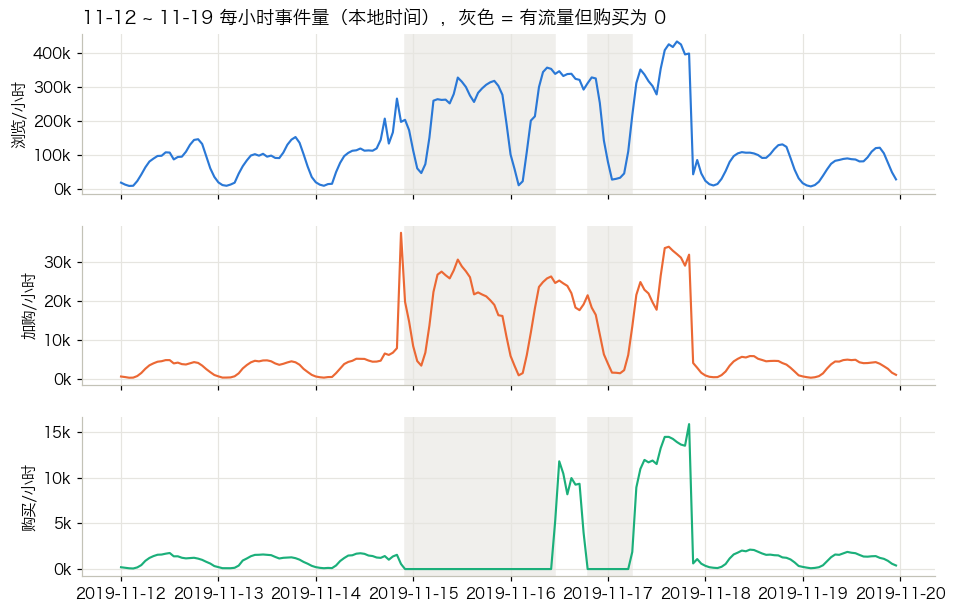

In [5]:
h = q("""
    SELECT event_hour_ts, views, carts, purchases
    FROM ads_hourly_events
    WHERE event_hour_ts BETWEEN '2019-11-12' AND '2019-11-19 23:00'
    ORDER BY 1
""")
fig, axes = plt.subplots(3, 1, figsize=(10, 6.4), sharex=True)
for ax, col, name, c in zip(axes, ["views", "carts", "purchases"], ["浏览", "加购", "购买"], PALETTE[:3]):
    ax.plot(h.event_hour_ts, h[col], color=c, linewidth=1.4)
    ax.set_ylabel(f"{name}/小时")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
gap = h[(h.purchases == 0) & (h.views > 5000)]
for ax in axes:
    for _, g in gap.groupby((gap.event_hour_ts.diff() != pd.Timedelta(hours=1)).cumsum()):
        ax.axvspan(g.event_hour_ts.min(), g.event_hour_ts.max() + pd.Timedelta(hours=1), color=SHADE, zorder=0)
axes[0].set_title("11-12 ~ 11-19 每小时事件量（本地时间），灰色 = 有流量但购买为 0")
plt.show()

**第一步：看形状。** 购买量在本地 11-14 22:00 整点归零，连续 37 个小时没有一条，11-16 11:00 整点恢复，
当晚 19:00 又归零 11 个小时。业务波动是渐变的，不会整点断崖、整点恢复，这更像采集链路故障。

**第二步：看别的事件。** 同一时段浏览、加购都在正常记录，而且比平时还高（大促在进行）。
所以不是整站或整条日志链路宕机，是 purchase 这一个事件丢了。

**第三步：丢了还是晚到了？** 如果购买只是延迟上报，恢复后会集中补进一批「前几天 session 的购买」。

In [6]:
q("""
    WITH s AS (SELECT user_session, CAST(MIN(event_time) AS DATE) AS session_start FROM dwd_events GROUP BY 1)
    SELECT e.event_date AS 购买日期, s.session_start AS session开始日期, COUNT(*) AS 购买事件数
    FROM dwd_events e JOIN s USING (user_session)
    WHERE e.event_type = 'purchase' AND e.event_date IN ('2019-11-13', '2019-11-17', '2019-11-20')
    GROUP BY 1, 2 HAVING COUNT(*) > 100
    ORDER BY 1, 2
""")

,购买日期,session开始日期,购买事件数
0,2019-11-13,2019-11-13,22458
1,2019-11-17,2019-11-17,184479
2,2019-11-20,2019-11-20,24913


恢复后（11-17）的购买全部属于当天开始的 session，没有任何前两天的购买被补进来，和正常日（11-13、11-20）一样。
**结论：是丢失，不是延迟上报。**

**第四步：会不会是购买被误记成了加购？** 中断期加购量暴涨到平时的 4–5 倍，如果是误记，
应该会出现大量「刚加购同一商品又加购一次」（原本那一下是购买）。

In [7]:
q("""
    WITH c AS (
        SELECT
            event_time,
            event_time - LAG(event_time) OVER (PARTITION BY user_session, product_id ORDER BY event_time) AS since_prev,
            CASE
                WHEN event_time BETWEEN '2019-11-14 22:00' AND '2019-11-16 10:59:59' THEN '2 埋点中断期'
                WHEN event_date BETWEEN '2019-11-10' AND '2019-11-13' THEN '1 正常日（11-10~11-13）'
                WHEN event_date = '2019-11-17' THEN '3 大促日、购买正常记录（11-17）'
            END AS period
        FROM dwd_events
        WHERE event_type = 'cart' AND event_date BETWEEN '2019-11-10' AND '2019-11-17'
    )
    SELECT period AS 时段, COUNT(*) AS 加购事件,
           AVG(CASE WHEN since_prev <= INTERVAL 10 MINUTE THEN 1 ELSE 0 END) AS "10分钟内重复加购同一商品"
    FROM c WHERE period IS NOT NULL
    GROUP BY 1 ORDER BY 1
""")

,时段,加购事件,10分钟内重复加购同一商品
0,1 正常日（11-10~11-13）,279202,0.2667
1,2 埋点中断期,656382,0.2955
2,3 大促日、购买正常记录（11-17）,416828,0.3003


中断期的重复加购比例和 11-17（购买正常记录的大促日）几乎一样，只比平时略高。
加购暴涨是大促期间真实的加购行为，**没有证据表明购买被误记成加购**。

**处理方式**（同时写进了 `docs/data_quality_report.md`）：

- 不插补。插补需要假设大促期间的转化率，而那正是想知道的东西；
- 看板上 11-15、11-16 的购买类指标标灰，环比和基线计算跳过这两天；
- 依赖购买的分析避开这两天，或写明会**低估** GMV（对召回价值的估计因此偏保守）；
- 大促复盘（notebook 06）只用不受影响的指标。旧版得出的「大促前段只加购不下单、后段集中清算购物车」不成立——前段的购买根本没记下来；
- 业务里应补的监控：purchase 小时量低于上周同时段 30% 时告警，这次能提前 30 多个小时发现（见 `docs/tracking_plan.md`）。

## 5. 自动化质量检查结果

`pipeline/quality_checks.py` 每次跑完管道都会重新检查一遍，完整报告见 [docs/data_quality_report.md](../docs/data_quality_report.md)。

In [8]:
report = (Path("..") / "docs" / "data_quality_report.md").read_text()
rows = [l.strip("|").split("|") for l in report.splitlines() if l.startswith("| ") and "检查项" not in l]
dq = pd.DataFrame([[c.strip() for c in r] for r in rows], columns=["类别", "检查项", "结果", "说明"])
print(dq.结果.str.split().str[-1].value_counts().to_dict())
dq.style.hide(axis="index").set_properties(**{"text-align": "left"})

{'PASS': 16, 'WARN': 9}


类别,检查项,结果,说明
行数对账,ODS 行数 = 原始 CSV 行数,✅ PASS,"ODS 109,950,743 行；原始 2019-Oct.csv 42,448,764 + 2019-Nov.csv 67,501,979 = 109,950,743"
行数对账,ODS → DWD 剔除行可解释,✅ PASS,"完全重复 130,739 行（0.119%）；时区平移后落到 12-01 的 47,351 行；DWD 剩 109,772,653 行"
唯一性,"dws_user_daily 主键 (user_id, event_date) 唯一",✅ PASS,"15,094,690 行 / 15,094,690 个主键"
唯一性,"dwd_orders 主键 (user_id, order_id) 唯一",✅ PASS,"1,402,222 笔订单"
唯一性,dws_user_profile 一个用户一行,✅ PASS,"5,315,091 个用户"
唯一性,一个 session 只属于一个用户,⚠️ WARN,跨用户共用的 session：938 个
完整性,user_id 空值率,✅ PASS,0 行（0.0000%）
完整性,event_time_utc 空值率,✅ PASS,0 行（0.0000%）
完整性,event_type 空值率,✅ PASS,0 行（0.0000%）
完整性,product_id 空值率,✅ PASS,0 行（0.0000%）
